In [1]:
!mamba install numpy
!mamba install scikit-learn
!mamba install matplotlib
!mamba install seaborn
!mamba install pandas

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 5.132 seconds
  Name  Version  Build         Channel
--------------------------------------------
- pip   26.2.2   pyh145f28c_0  conda-forge
mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, scikit-learn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 1.975 seconds
  Name                Version     Build                Channel
----------------------------------------------------------------------------
+ ca-certificates     2026.10.23  hbd8a1cb_0           conda-forge
+ certifi             2026.10.23  pyhd8ed1ab_3         conda-forge
+ charset-normalizer  3.5.1       pyhd8ed1ab_0         conda-forge
+ idna                3.20        pyh5ded981_0         conda-forge
+ joblib              1.6.0       py313h57e9779_0      emscript

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv("28-urban_pedestrian_locations_with_labels.csv")

In [4]:
df.head()

,x_position,y_position,true_cluster
0,0.830586,-0.447733,1
1,0.701678,0.816918,0
2,1.022080,-0.492571,1
3,-0.316765,0.953438,0
4,0.293226,1.057185,0


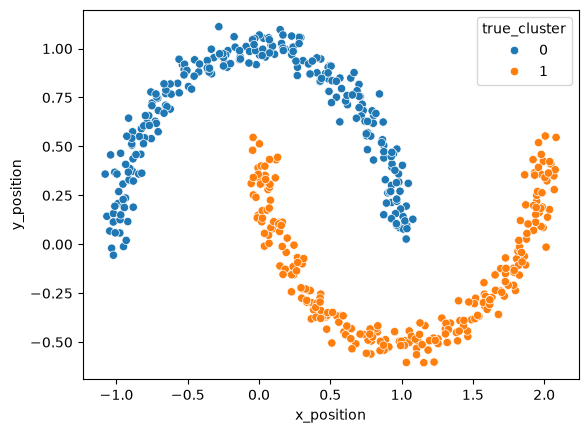

In [6]:
sns.scatterplot(data=df, x="x_position" ,y ="y_position", hue="true_cluster")
plt.show()

In [24]:
df=df.drop("true_cluster",axis=1)

In [25]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   x_position  500 non-null    float64
 1   y_position  500 non-null    float64
dtypes: float64(2)
memory usage: 7.9 KB


In [26]:
from sklearn.preprocessing import StandardScaler

In [27]:
scaler=StandardScaler()

In [28]:
X_scaled=scaler.fit_transform(df)

In [29]:
from sklearn.cluster import DBSCAN

In [30]:
dbscan=DBSCAN()

In [31]:
dbscan.fit(X_scaled)

,"eps eps: float, default=0.5The maximum distance between two samples for one to be consideredas in the neighborhood of the other. This is not a maximum boundon the distances of points within a cluster. This is the mostimportant DBSCAN parameter to choose appropriately for your data setand distance function. Smaller values generally lead to more clusters.",0.5
,"min_samples min_samples: int, default=5The number of samples (or total weight) in a neighborhood for a point tobe considered as a core point. This includes the point itself. If`min_samples` is set to a higher value, DBSCAN will find denser clusters,whereas if it is set to a lower value, the found clusters will be moresparse.",5
,"metric metric: str, or callable, default='euclidean'The metric to use when calculating distance between instances in afeature array. If metric is a string or callable, it must be one ofthe options allowed by :func:`sklearn.metrics.pairwise_distances` forits metric parameter.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors for DBSCAN... versionadded:: 0.17 metric *precomputed* to accept precomputed sparse matrix.",'euclidean'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function... versionadded:: 0.19",None
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'The algorithm to be used by the NearestNeighbors moduleto compute pointwise distances and find nearest neighbors.'auto' will attempt to decide the most appropriate algorithmbased on the values passed to :meth:`fit` method.See :class:`~sklearn.neighbors.NearestNeighbors` documentation fordetails.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or cKDTree. This can affect the speedof the construction and query, as well as the memory requiredto store the tree. The optimal value dependson the nature of the problem.",30
,"p p: float, default=NoneThe power of the Minkowski metric to be used to calculate distancebetween points. If None, then ``p=2`` (equivalent to the Euclideandistance). When p=1, this is equivalent to Manhattan distance.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
Name,Type,Value
"components_ components_: ndarray of shape (n_core_samples, n_features)Copy of each core sample found by training.","ndarray[float64](500, 2)","[[ 0.38,-1.4 ], [ 0.23, 1.14], [ 0.6 ,-1.49], ..., [ 0.1 ,-1.24], [ 1.28,-1.07], [-0.32, 1.63]]"
"core_sample_indices_ core_sample_indices_: ndarray of shape (n_core_samples,)Indices of core samples.","ndarray[int32](500,)","[ 0, 1, 2,...,497,498,499]"


In [32]:
dbscan.labels_

array([0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1,
       0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1,
       1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1,
       0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1,
       0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1,
       0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1,
       1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1,
       0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1,
       0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1,
       1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0,

In [33]:
X_scaled = pd.DataFrame(X_scaled, columns = ["x_position", "y_position"])

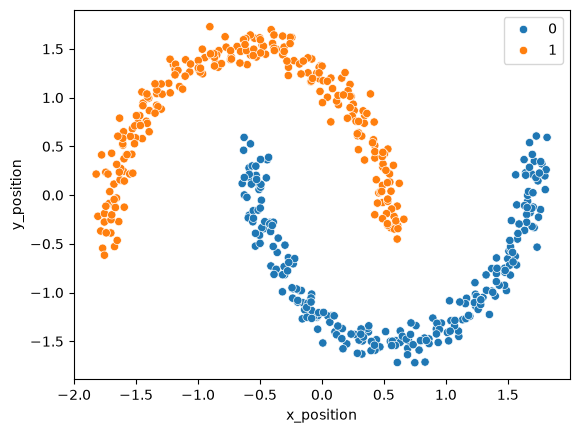

In [35]:
sns.scatterplot(data=X_scaled,x="x_position",y="y_position",hue=dbscan.labels_)
plt.show()

In [36]:
df=pd.read_csv("28-urban_pedestrian_locations_with_labels.csv")

In [38]:
df.columns

Index(['x_position', 'y_position', 'true_cluster'], dtype='str')

In [39]:
eps_values = [0.1,0.2,0.3,0.4,0.5,0.6]
min_samples_values = [4,5,6]

In [40]:
from sklearn.metrics import silhouette_score

In [42]:
results = []

for epsilon in eps_values:
    for min_samples in min_samples_values:
        db = DBSCAN(eps=epsilon, min_samples=min_samples).fit(X_scaled)
        labels = db.labels_
        # Skip if all points are noise or only one cluster found
        if len(set(labels)) <= 1:
            continue
        
        silhouette = silhouette_score(X_scaled, labels)
        
        results.append({
            'eps': epsilon,
            'min_samples': min_samples,
            'Silhouette': silhouette,
            'n_clusters': len(set(labels)) - (1 if -1 in labels else 0)
        })

# Convert to DataFrame and sort by silhouette 
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by='Silhouette', ascending=False)

In [45]:
results_df

,eps,min_samples,Silhouette,n_clusters
9,0.4,4,0.389338,2
10,0.4,5,0.389338,2
16,0.6,5,0.389338,2
15,0.6,4,0.389338,2
14,0.5,6,0.389338,2
13,0.5,5,0.389338,2
12,0.5,4,0.389338,2
11,0.4,6,0.389338,2
17,0.6,6,0.389338,2
8,0.3,6,0.389338,2


In [46]:
from sklearn.cluster import HDBSCAN

In [47]:
hdscan=HDBSCAN()

In [48]:
hdscan.fit(X_scaled)

/lib/python3.13/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


,"min_cluster_size min_cluster_size: int, default=5The minimum number of samples in a group for that group to beconsidered a cluster; groupings smaller than this size will be leftas noise.",5
,"min_samples min_samples: int, default=NoneThe parameter `k` used to calculate the distance between a point`x_p` and its k-th nearest neighbor.When `None`, defaults to `min_cluster_size`.",None
,"cluster_selection_epsilon cluster_selection_epsilon: float, default=0.0A distance threshold. Clusters below this value will be merged.See [5]_ for more information.",0.0
,"max_cluster_size max_cluster_size: int, default=NoneA limit to the size of clusters returned by the `""eom""` clusterselection algorithm. There is no limit when `max_cluster_size=None`.Has no effect if `cluster_selection_method=""leaf""`.",None
,"metric metric: str or callable, default='euclidean'The metric to use when calculating distance between instances in afeature array.- If metric is a string or callable, it must be one of the options allowed by :func:`~sklearn.metrics.pairwise_distances` for its metric parameter.- If metric is ""precomputed"", X is assumed to be a distance matrix and must be square.",'euclidean'
,"metric_params metric_params: dict, default=NoneArguments passed to the distance metric.",None
,"alpha alpha: float, default=1.0A distance scaling parameter as used in robust single linkage.See [3]_ for more information.",1.0
,"algorithm algorithm: {""auto"", ""brute"", ""kd_tree"", ""ball_tree""}, default=""auto""Exactly which algorithm to use for computing core distances; By defaultthis is set to `""auto""` which attempts to use a:class:`~sklearn.neighbors.KDTree` tree if possible, otherwise it usesa :class:`~sklearn.neighbors.BallTree` tree. Both `""kd_tree""` and`""ball_tree""` algorithms use the:class:`~sklearn.neighbors.NearestNeighbors` estimator.If the `X` passed during `fit` is sparse or `metric` is invalid forboth :class:`~sklearn.neighbors.KDTree` and:class:`~sklearn.neighbors.BallTree`, then it resolves to use the`""brute""` algorithm.",'auto'
,"leaf_size leaf_size: int, default=40Leaf size for trees responsible for fast nearest neighbour queries whena KDTree or a BallTree are used as core-distance algorithms. A largedataset size and small `leaf_size` may induce excessive memory usage.If you are running out of memory consider increasing the `leaf_size`parameter. Ignored for `algorithm=""brute""`.",40
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel to calculate distances.`None` means 1 unless in a :obj:`joblib.parallel_backend` context.`-1` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"cluster_selection_method cluster_selection_method: {""eom"", ""leaf""}, default=""eom""The method used to select clusters from the condensed tree. Thestandard approach for HDBSCAN* is to use an Excess of Mass (`""eom""`)algorithm to find the most persistent clusters. Alternatively you caninstead select the clusters at the leaves of the tree -- this providesthe most fine grained and homogeneous clusters.",'eom'


In [49]:
hdscan.labels_

array([0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1,
       0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1,
       1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1,
       0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1,
       0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1,
       0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1,
       1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1,
       0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1,
       0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1,
       1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0,

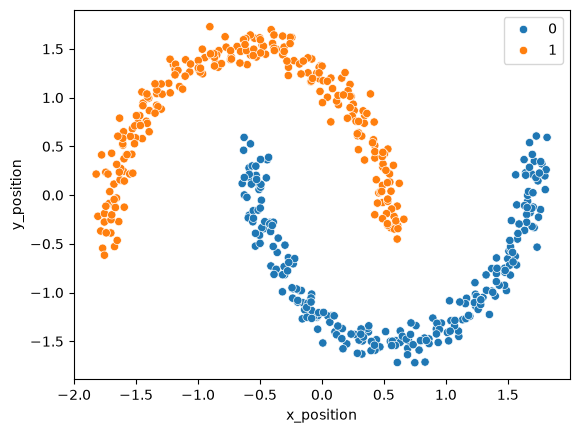

In [50]:
sns.scatterplot(data=X_scaled, x="x_position" , y="y_position" , hue=hdscan.labels_)
plt.show()

In [57]:
min_cluster_sizes=[3, 5, 7, 10]
min_sample=[None, 3, 5, 7]

In [58]:
results = []

for min_cluster_size in min_cluster_sizes:
    for min_samples in min_sample:
        hdbscan = HDBSCAN(min_cluster_size, min_samples=min_samples).fit(X_scaled)
        labels = hdbscan.labels_
        # Skip if all points are noise or only one cluster found
        if len(set(labels)) <= 1:
            continue
        
        silhouette = silhouette_score(X_scaled, labels)
        
        results.append({
            'min_samples_values':min_samples_values,
            'min_samples': min_samples,
            'Silhouette': silhouette,
            'n_clusters': len(set(labels)) - (1 if -1 in labels else 0)
        })

# Convert to DataFrame and sort by silhouette 
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by='Silhouette', ascending=False)

/lib/python3.13/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
/lib/python3.13/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
/lib/python3.13/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
/lib/python3.13/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
/lib/python3.13/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` wi

In [60]:
results_df

,min_samples_values,min_samples,Silhouette,n_clusters
2,"[4, 5, 6]",5.0,0.389338,2
3,"[4, 5, 6]",7.0,0.389338,2
4,"[4, 5, 6]",NaN,0.389338,2
5,"[4, 5, 6]",3.0,0.389338,2
6,"[4, 5, 6]",5.0,0.389338,2
7,"[4, 5, 6]",7.0,0.389338,2
8,"[4, 5, 6]",NaN,0.389338,2
9,"[4, 5, 6]",3.0,0.389338,2
10,"[4, 5, 6]",5.0,0.389338,2
11,"[4, 5, 6]",7.0,0.389338,2
